## Transformación y reducción de datos: la matriz X·y

**Resumen ejecutivo**
- **Problema.** Con la hipoteca al 90 % LTV y 25 años, ninguna región es accesible para un joven: esfuerzo medio 0,63 (rango 0,42-1,07) frente al umbral del 30 %.
- **Producto.** Matriz X·y con 60 filas × 19 columnas (9 rasgos estandarizados + 10 dummies de región) lista para el modelado.
- **Método.** `StandardScaler` + `OneHotEncoder` dentro de un `ColumnTransformer`: escala y codifica en un solo estimador y se reajusta por pliegue en el modelado (sin fuga de datos).
- **Hallazgo.** La zona domina (London ≈ 3,4× North East) y el clima acompaña en la mayoría de las zonas (lluvia con signo negativo en 8 de 10).

**Preparación para el modelado.** Con el cuadro maestro ya cruzado (60 filas, 10 regiones × 6 años) se construye la **matriz X** (rasgos) y el **objetivo y** (esfuerzo hipotecario por región y año) que el modelado usará.

**Método utilizado:** estandarización `StandardScaler` de los rasgos numéricos + one-hot (`OneHotEncoder`) de la región dentro de un `ColumnTransformer` (mismo pipeline del modelado). Se guarda en `data/integrado/matriz_features.parquet`.

## 1. Raíz del proyecto y dependencias

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.preprocessing import StandardScaler

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
sys.path.insert(0, str(PROYECTO / "script"))

from proyecto import config

print("raiz del proyecto:", PROYECTO.name)
print("dependencias: numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__)

raiz del proyecto: mineria
dependencias: numpy 2.5.2 | pandas 3.0.5 | sklearn 1.9.1


## 2. Insumo: el cuadro maestro

`maestro_joven_uk.parquet` es la salida del cruzamiento de las fuentes: precio mediano,
salario joven regional, anomalías climáticas y años de salario por región y año.
También se carga la oferta hipotecaria 2022 ya limpia (tasa media winsorizada y
comisiones promedio).

In [2]:
maestro = pd.read_parquet(config.RUTA_MAESTRO).sort_values(["region", "anio"])
hipotecas = pd.read_parquet(config.RUTA_HIPOTECAS_LIMPIO)

print(f"maestro: {maestro.shape[0]} filas | anios {maestro['anio'].min()}-{maestro['anio'].max()} "
      f"| regiones {maestro['region'].nunique()}")
print("columnas:", list(maestro.columns))
print("\nnulos en candidatos a rasgos:")
columnas = ["tmax_anom", "tmin_anom", "lluvia_anom", "sol_anom",
            "af_anom", "precio_var_pct", "anos_salario"]
print(maestro[columnas].isna().sum().to_string())

maestro: 60 filas | anios 2015-2020 | regiones 10
columnas: ['anio', 'region', 'n_transacciones', 'precio_medio', 'precio_mediana', 'salario_mediana_real', 'salario_joven_nacional', 'factor_regional', 'salario_joven_region', 'tmax_anom', 'tmin_anom', 'lluvia_anom', 'sol_anom', 'af_anom', 'precio_var_pct', 'anos_salario']

nulos en candidatos a rasgos:
tmax_anom          0
tmin_anom          0
lluvia_anom        0
sol_anom          18
af_anom            0
precio_var_pct    10
anos_salario       0


## 3. Objetivo (y): el esfuerzo hipotecario

$\text{esfuerzo} = \dfrac{\text{cuota mensual PMT}}{\text{salario joven mensual}}$.

La cuota usa el 90 % del precio mediano (LTV), 25 años, la tasa inicial media
winsorizada y las comisiones promedio de la oferta 2022.

*Nota de moneda:* los precios de la ventana son nominales y el salario de F4 está
en GBP-2020; en el corte 2022 del informe el precio se deflacta
(`config.DEFLACTOR_2022_A_2020`). El esfuerzo aquí es una serie homogénea
por año y región para el modelado.

In [3]:
from proyecto import config
from proyecto import indicadores

tasa = float(hipotecas["tasa_inicial_pct"].mean())
comisiones = float(hipotecas["comisiones_total"].mean())

def esfuerzo_fila(precio):
    cuota = indicadores.cuota_mensual_pmt(precio, tasa, comisiones=comisiones)
    return cuota

df = maestro.copy()
df["esfuerzo"] = (df["precio_mediana"].apply(esfuerzo_fila)
                  / (df["salario_joven_region"] / 12.0))

print(f"tasa winsorizada {tasa:.2f} % | comisiones GBP {comisiones:,.0f} "
      f"| LTV {config.LTV:.0%} | {config.PLAZO_ANIOS} anios")
for region, valor in df.groupby("region", observed=True)["esfuerzo"].mean().sort_values().items():
    estado = "accesible" if valor <= config.UMBRAL_ACCESIBILIDAD else "no accesible"
    print(f"  {region:<26} esfuerzo medio {valor:.3f} -> {estado}")
print("\numbral 30 % de la regla de negocio (config.UMBRAL_ACCESIBILIDAD).")

tasa winsorizada 6.04 % | comisiones GBP 1,116 | LTV 90% | 25 anios
  North East                 esfuerzo medio 0.434 -> no accesible
  North West                 esfuerzo medio 0.472 -> no accesible
  Wales                      esfuerzo medio 0.478 -> no accesible
  Yorkshire and The Humber   esfuerzo medio 0.488 -> no accesible
  East Midlands              esfuerzo medio 0.547 -> no accesible
  West Midlands              esfuerzo medio 0.561 -> no accesible
  South West                 esfuerzo medio 0.712 -> no accesible
  East of England            esfuerzo medio 0.752 -> no accesible
  South East                 esfuerzo medio 0.813 -> no accesible
  London                     esfuerzo medio 0.996 -> no accesible

umbral 30 % de la regla de negocio (config.UMBRAL_ACCESIBILIDAD).


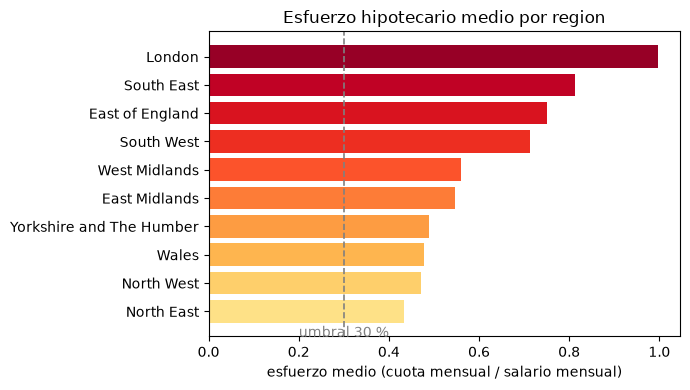

In [4]:
# Esfuerzo medio por region (2015-2020)
fig, ax = plt.subplots(figsize=(7, 4))
orden = df.groupby("region", observed=True)["esfuerzo"].mean().sort_values()
colores = plt.cm.YlOrRd(np.linspace(0.2, 0.95, len(orden)))
ax.barh(orden.index, orden.values, color=colores)
ax.axvline(config.UMBRAL_ACCESIBILIDAD, color="gray", ls="--", lw=1.2)
ax.text(config.UMBRAL_ACCESIBILIDAD, -0.9, "umbral 30 %", color="gray", ha="center")
ax.set_xlabel("esfuerzo medio (cuota mensual / salario mensual)")
ax.set_title("Esfuerzo hipotecario medio por region")
plt.tight_layout()
plt.show()

Cada barra muestra el esfuerzo medio por región (la línea punteada es el umbral del 30 % del salario). Ninguna zona es accesible: Londres consume casi todo el salario (0,99) y North East el 43 %.

## 4. Método de preparación

- **Rasgos numéricos** (9): precio mediano, salario joven regional, anomalías de
  temperatura/lluvia/sol/frost, variación anual del precio y años de salario.
  Se estandarizan con `StandardScaler` (media 0, desv 1): el precio está en
  libras y el clima en grados/mm, unidades distintas que deben equilibrarse.
- **Nulos:** `sol_anom` (18) y `precio_var_pct` (10, primer año de cada región)
  se imputan a 0 como valor neutral.
- **Región (nominal):** se codifica one-hot con `OneHotEncoder` dentro de un `ColumnTransformer`, el mismo estimador que se ajustará en el modelado.
- **Pipeline (`ColumnTransformer`):** se incorpora porque escala y codifica en un solo estimador, el mismo patrón del modelado, donde se ajustará dentro de cada pliegue para no filtrar datos.
- Quedan fuera de X por ser agrupadores o derivados: `anio`, `region`,
  `n_transacciones`, `precio_medio` (redundante con la mediana) y las escalas
  del salario. La imputación y el escalado se reajustarán dentro de cada pliegue
  durante el entrenamiento (sin fuga de datos).

In [5]:
# 4. Metodo: pipeline de transformacion con ColumnTransformer
#    Mismo patron que se usara en el modelado (ajuste dentro de cada pliegue).
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

RASGOS = ["precio_mediana", "salario_joven_region", "tmax_anom", "tmin_anom",
          "lluvia_anom", "sol_anom", "af_anom", "precio_var_pct", "anos_salario"]

df["sol_anom"] = df["sol_anom"].fillna(0.0)              # 0 = sin anomalia
df["precio_var_pct"] = df["precio_var_pct"].fillna(0.0)  # primer anio: variacion nula

preprocesador = ColumnTransformer(
    transformers=[
        ("escala", StandardScaler(), RASGOS),
        ("region", OneHotEncoder(sparse_output=False), ["region"]),
    ],
    remainder="drop",
)

z = preprocesador.fit_transform(df[RASGOS + ["region"]])
col_region = [f"region_{v}" for v in
              preprocesador.named_transformers_["region"].categories_[0]]
x = pd.DataFrame(z, columns=[f"z_{c}" for c in RASGOS] + col_region,
                 index=df.index)
y = df["esfuerzo"].astype(float).rename("esfuerzo")

print("StandardScaler tras ajustar: media %.4f / desv %.3f"
      % (float(z[:, : len(RASGOS)].mean()), float(z[:, : len(RASGOS)].std())))
print(f"one-hot de region via OneHotEncoder: {len(col_region)} columnas")
display(x.iloc[:5, :4])


StandardScaler tras ajustar: media 0.0000 / desv 1.000
one-hot de region via OneHotEncoder: 10 columnas


,z_precio_mediana,z_salario_joven_region,z_tmax_anom,z_tmin_anom
0,-0.687859,-0.344264,0.237168,0.332304
1,-0.608202,-0.314691,-0.320078,0.371052
2,-0.470130,-0.441223,0.118964,1.133096
3,-0.390473,-0.485214,0.777527,0.668120
4,-0.342678,-0.469021,0.406030,0.500212


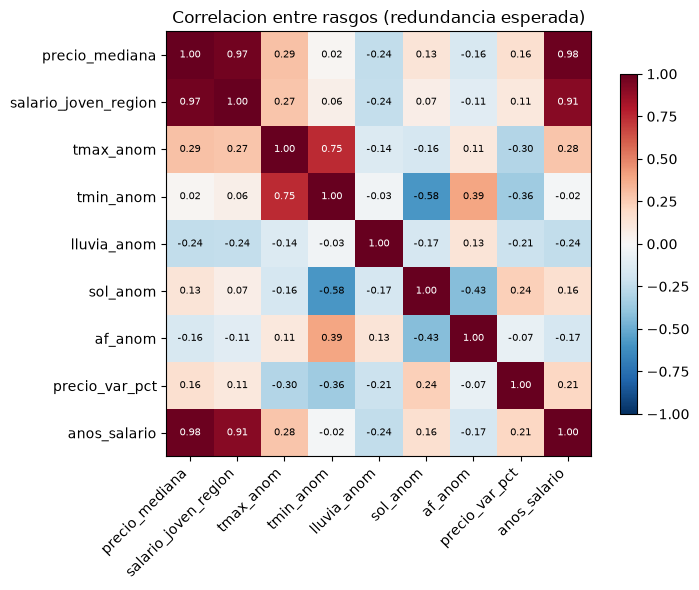

In [6]:
# Correlacion entre los rasgos numericos (matriz X)
corr = df[RASGOS].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=7, color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlacion entre rasgos (redundancia esperada)")
plt.tight_layout()
plt.show()

Cada celda es la correlación entre dos rasgos: precio, salario y años de salario se correlacionan, igual que tmin y tmax. Eso marca redundancia (posible colinealidad) que conviene revisar antes de interpretar coeficientes.

## 5. Matriz X·y final

X = rasgos numéricos **escalados** (prefijo `z_`) + one-hot de región (pipeline `ColumnTransformer`).
y = esfuerzo por región y año. `anio` y `region` se conservan como
identificadores de fila, no como rasgos de entrada.

In [7]:
# x y ya quedaron construidos en la seccion 4 (pipeline ColumnTransformer)
y = df["esfuerzo"].astype(float).rename("esfuerzo")

print(f"X {x.shape} | y {y.shape[0]} | nulos en X: {int(x.isna().sum().sum())}")
print(f"esfuerzo: media {y.mean():.3f} | rango {y.min():.3f}-{y.max():.3f}")

print("\nMatriz y (esfuerzo) por region y anio: 10 regiones x 6 anios")
tab = y.to_frame().assign(region=df["region"], anio=df["anio"].astype(int))
display(tab.pivot(index="region", columns="anio", values="esfuerzo").round(3))

print("\nDistribucion del esfuerzo (y):")
tramos_y = pd.cut(y, bins=[0, 0.3, 0.5, 0.7, 1.0, 2.0], right=False)
display(tramos_y.value_counts(normalize=True).sort_index().round(3)
        .to_frame(name="proporcion"))

assert len(x) == len(y) == 60, "la matriz no tiene 60 filas"
assert int(x.isna().sum().sum()) == 0, "la matriz X tiene nulos"
assert bool(y.gt(0).all()), "el esfuerzo debe ser positivo"
print("validado: 60 filas, sin nulos, esfuerzo positivo")

X (60, 19) | y 60 | nulos en X: 0
esfuerzo: media 0.625 | rango 0.416-1.065

Matriz y (esfuerzo) por region y anio: 10 regiones x 6 anios


anio,2015,2016,2017,2018,2019,2020
region,,,,,,
East Midlands,0.476,0.497,0.545,0.571,0.583,0.608
East of England,0.647,0.699,0.765,0.784,0.796,0.820
London,0.883,0.962,1.013,1.022,1.030,1.065
North East,0.416,0.418,0.431,0.443,0.449,0.449
North West,0.428,0.442,0.464,0.482,0.497,0.517
South East,0.708,0.762,0.822,0.848,0.851,0.886
South West,0.629,0.663,0.710,0.744,0.742,0.785
Wales,0.439,0.450,0.469,0.488,0.502,0.522
West Midlands,0.494,0.515,0.557,0.581,0.596,0.623



Distribucion del esfuerzo (y):


,proporcion
esfuerzo,
"[0.0, 0.3)",0.000
"[0.3, 0.5)",0.350
"[0.5, 0.7)",0.317
"[0.7, 1.0)",0.267
"[1.0, 2.0)",0.067


validado: 60 filas, sin nulos, esfuerzo positivo


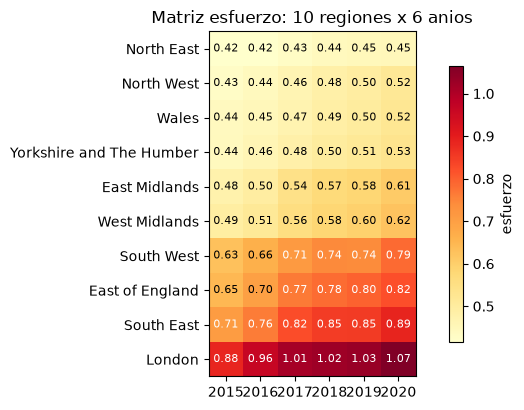

In [8]:
# Matriz y (esfuerzo) por region y anio
mat = y.to_frame().assign(region=df["region"], anio=df["anio"].astype(int))
mat = mat.pivot(index="region", columns="anio", values="esfuerzo")
mat = mat.sort_values(mat.columns[-1])
fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(mat, cmap="YlOrRd")
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=8, color="white" if mat.iloc[i, j] > 0.7 else "black")
fig.colorbar(im, shrink=0.8, label="esfuerzo")
ax.set_title("Matriz esfuerzo: 10 regiones x 6 anios")
plt.tight_layout()
plt.show()

El esfuerzo crece año a año en todas las regiones y es mayor hacia el sur y el este; London y South East superan 1,0 desde ~2017.

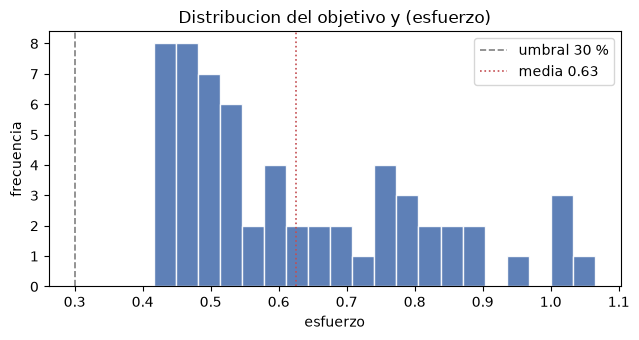

In [9]:
# Distribucion del objetivo (y)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(y, bins=20, color="#4C72B0", edgecolor="white", alpha=0.9)
ax.axvline(config.UMBRAL_ACCESIBILIDAD, color="gray", ls="--", lw=1.2,
           label=f"umbral 30 %")
ax.axvline(y.mean(), color="#C44E52", ls=":", lw=1.2, label=f"media {y.mean():.2f}")
ax.set_xlabel("esfuerzo")
ax.set_ylabel("frecuencia")
ax.legend()
ax.set_title("Distribucion del objetivo y (esfuerzo)")
plt.tight_layout()
plt.show()

El histograma agrupa los 60 esfuerzos: la media es 0,63 y todo queda a la derecha del umbral del 30 %, con asimetría y cola derecha en Londres. Es una variable positiva y acotada para regresión.

## 6. Resultados clave

Cifras de la matriz X·y que resumen la preparacion y sirven de contexto para
el modelado: estadisticas del objetivo, evolucion por anio y las zonas extremas.

In [10]:
print(f"Matriz X·y: {x.shape[0]} filas x {x.shape[1]} columnas X "
      f"(9 z_ + 10 region_) | nulos {int(x.isna().sum().sum())}")
print(f"y: media {y.mean():.3f} | mediana {y.median():.3f} | "
      f"Q1 {y.quantile(0.25):.3f} | Q3 {y.quantile(0.75):.3f} | "
      f"rango {y.min():.3f}-{y.max():.3f}")

print("\nEsfuerzo medio por anio (todas las regiones):")
print(df.groupby("anio")["esfuerzo"].mean().round(3).to_string())

print("\nZonas de mayor esfuerzo (top 3):")
print(df.nlargest(3, "esfuerzo").loc[:, ["region", "anio", "esfuerzo"]]
      .round(3).to_string(index=False))
print("Zonas de menor esfuerzo (bottom 3):")
print(df.nsmallest(3, "esfuerzo").loc[:, ["region", "anio", "esfuerzo"]]
      .round(3).to_string(index=False))

print("\nFrecuencias de regiones-anio: "
      f">=0.7 -> {(y >= 0.7).sum()} | >=1.0 -> {(y >= 1.0).sum()} (of {len(y)})")

Matriz X·y: 60 filas x 19 columnas X (9 z_ + 10 region_) | nulos 0
y: media 0.625 | mediana 0.564 | Q1 0.479 | Q3 0.763 | rango 0.416-1.065

Esfuerzo medio por anio (todas las regiones):
anio
2015    0.556
2016    0.587
2017    0.626
2018    0.646
2019    0.656
2020    0.681

Zonas de mayor esfuerzo (top 3):
region  anio  esfuerzo
London  2020     1.065
London  2019     1.030
London  2018     1.022
Zonas de menor esfuerzo (bottom 3):
    region  anio  esfuerzo
North East  2015     0.416
North East  2016     0.418
North West  2015     0.428

Frecuencias de regiones-anio: >=0.7 -> 20 | >=1.0 -> 4 (of 60)


### Clima y zona

La base transaccional (11.369.413 adquisiciones) aporta la **localización** y el
**precio** de cada casa; el cuadro maestro la cruza con los **salarios jovenes**,
el **clima** y las regiones. Aquí se mide la asociacion (Pearson, no causalidad)
entre las anomalías climáticas y el precio/hipoteca, y luego la brecha por zona.

In [11]:
# Correlaciones clima vs precio y hipoteca (asociacion, no causalidad)
clima = ["tmax_anom", "tmin_anom", "lluvia_anom", "sol_anom", "af_anom"]
corr_clima = pd.DataFrame({
    "hipoteca (esfuerzo)": [df["esfuerzo"].corr(df[cl]) for cl in clima],
    "precio_var_pct": [df["precio_var_pct"].corr(df[cl]) for cl in clima],
}, index=clima).round(3)
display(corr_clima)

,hipoteca (esfuerzo),precio_var_pct
tmax_anom,0.277,-0.296
tmin_anom,-0.019,-0.357
lluvia_anom,-0.245,-0.214
sol_anom,0.156,0.235
af_anom,-0.165,-0.074


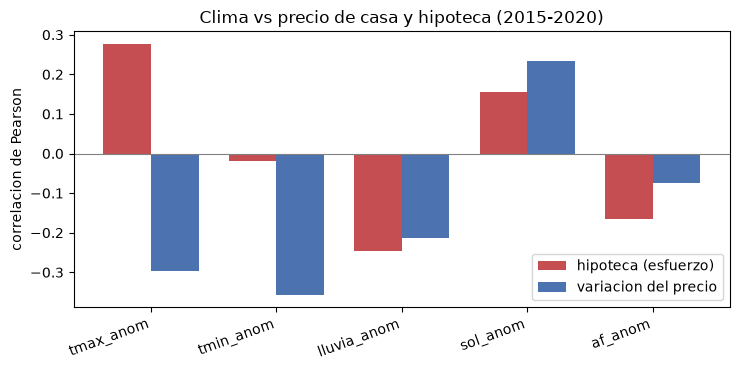

In [12]:
# Figura: asociacion global clima vs precio e hipoteca
fig, ax = plt.subplots(figsize=(7.5, 3.8))
posiciones = np.arange(len(clima)); w = 0.38
ax.bar(posiciones - w/2, corr_clima["hipoteca (esfuerzo)"], w, label="hipoteca (esfuerzo)", color="#C44E52")
ax.bar(posiciones + w/2, corr_clima["precio_var_pct"], w, label="variacion del precio", color="#4C72B0")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(posiciones); ax.set_xticklabels(clima, rotation=20, ha="right")
ax.set_ylabel("correlacion de Pearson")
ax.legend()
ax.set_title("Clima vs precio de casa y hipoteca (2015-2020)")
plt.tight_layout(); plt.show()

Las correlaciones entre el clima y el precio/la hipoteca son débiles a moderadas (r entre -0,36 y +0,28): más calor y sol se asocian con más subida nominal y más lluvia con menos, pero el clima no explica sola los precios.

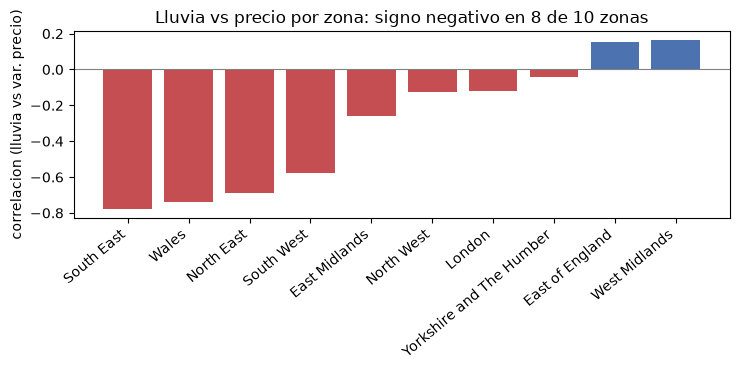

,region,r_lluvia
5,South East,-0.780
7,Wales,-0.739
3,North East,-0.687
6,South West,-0.577
0,East Midlands,-0.261
4,North West,-0.128
2,London,-0.118
9,Yorkshire and The Humber,-0.039
1,East of England,0.152
8,West Midlands,0.165


In [13]:
# Lluvia vs variacion del precio, por zona (¿afecta a la mayoria?)
r_zona = []
for reg, g in df.groupby("region", observed=True):
    r_zona.append((reg, g["lluvia_anom"].corr(g["precio_var_pct"])))
rz = pd.DataFrame(r_zona, columns=["region", "r_lluvia"]).sort_values("r_lluvia")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colores = np.where(rz["r_lluvia"] < 0, "#C44E52", "#4C72B0")
ax.bar(rz["region"], rz["r_lluvia"], color=colores)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(range(len(rz)))
ax.set_xticklabels(rz["region"], rotation=40, ha="right")
ax.set_ylabel("correlacion (lluvia vs var. precio)")
ax.set_title("Lluvia vs precio por zona: signo negativo en "
             f"{int((rz['r_lluvia'] < 0).sum())} de {len(rz)} zonas")
plt.tight_layout(); plt.show()
display(rz.round(3))

El signo lluvia-precio es negativo en 8 de 10 zonas: en años con más lluvia el precio sube menos (South East -0,78, Wales -0,74, North East -0,69). El clima sí se asocia al precio en la mayoría de las zonas, aunque con fuerza moderada.

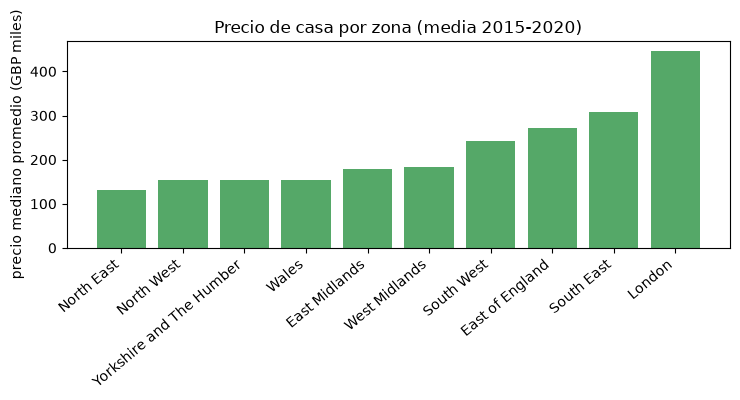

,GBP
region,
North East,131825.0
North West,153325.0
Yorkshire and The Humber,153500.0
Wales,153824.0
East Midlands,179750.0
West Midlands,182416.0
South West,242083.0
East of England,271667.0
South East,308333.0


In [14]:
# Precio mediano de casa por zona (media 2015-2020)
precio_zona = df.groupby("region", observed=True)["precio_mediana"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(precio_zona.index, precio_zona.values / 1e3, color="#55A868")
ax.set_xticks(range(len(precio_zona)))
ax.set_xticklabels(precio_zona.index, rotation=40, ha="right")
ax.set_ylabel("precio mediano promedio (GBP miles)")
ax.set_title("Precio de casa por zona (media 2015-2020)")
plt.tight_layout(); plt.show()
display(precio_zona.round(0).to_frame("GBP"))

El precio cambia mucho según la zona: London promedia ~GBP 445.000, 3,4 veces North East (~GBP 132.000), y la hipoteca hereda esa brecha (esfuerzo 0,99 vs 0,43). Por eso X combina las anomalías climáticas con las dummies de región, para separar el efecto de cada clima y el de la zona.

## 7. Guardar la matriz

Se guarda el parquet completo y la muestra (10 filas) que sí se sube al
repositorio. El mismo flujo corre en el terminal con
`python script/proyecto/transformaciones_s4.py`.

In [15]:
ruta = config.DATA_INTEGRADO / "matriz_features.parquet"
ruta_muestra = config.DATA_INTEGRADO / "matriz_features_muestra.parquet"
ruta.parent.mkdir(parents=True, exist_ok=True)

matriz = pd.concat([df[["region", "anio"]], x, y], axis=1)
matriz.to_parquet(ruta, index=False)
matriz.head(10).to_parquet(ruta_muestra, index=False)

print("guardado", str(ruta.relative_to(PROYECTO)), matriz.shape)
print("guardado", str(ruta_muestra.relative_to(PROYECTO)),
      matriz.head(10).shape)

guardado data\integrado\matriz_features.parquet (60, 22)
guardado data\integrado\matriz_features_muestra.parquet (10, 22)


## Cierre: decisiones de la preparación

1. **y (objetivo):** esfuerzo hipotecario `cuota PMT / salario joven mensual`, por región y año.
2. **Rasgos (9 numéricos):** precio mediano, salario joven regional, anomalías climáticas, variación anual del precio y años de salario; `anio` y `region` quedan como identificadores.
3. **Escalado:** `StandardScaler` (media 0, desv 1) para equilibrar unidades (GBP, %, mm).
4. **Codificación:** one-hot con `OneHotEncoder` dentro de un pipeline `ColumnTransformer` (escala + codifica juntos).
5. **Matriz X·y:** 60 filas × (9 escaladas + 10 dummies) → `data/integrado/matriz_features.parquet` (+ muestra de 10).

6. **Hallazgo clima y zona:** el precio de la casa y la hipoteca (esfuerzo) varían **por zona** (London ≈ 3,4x North East) y se asocian con el clima en la **mayoría de las zonas** (lluvia: signo negativo en 8 de 10 regiones, de intensidad débil-moderada).

Listo para que el modelado parta de `matriz_features.parquet`.

**Siguiente paso:** entrenar y evaluar con los mismos principios: imputación de nulos y escalado se ajustan solo en entrenamiento y se reutilizan en validación (sin fuga de datos).

## Técnicas que no se usan (y por qué)

- **MinMaxScaler y RobustScaler:** el `MinMaxScaler` mapea a [0,1] según `min`/`max` y lo distorsiona un solo valor extremo; el `RobustScaler` (mediana/IQR) sirve cuando hay outliers, pero nuestros datos ya pasaron la limpieza y la tasa fue winsorizada con IQR, así que no aporta frente a `StandardScaler` (queda como plan B si el modelado encuentra colas extremas).
- **KBinsDiscretizer:** discretizar `anos_salario` en tramos pierde precisión; el valor continuo explica mejor el esfuerzo. Solo sirve como lectura de negocio, por eso no forma parte de X.
- **PCA (reducción):** la figura de correlación de la sección 4 muestra la redundancia entre rasgos (precio-salario y tmin/tmax), pero con 60 filas y 19 columnas no hace falta comprimir, y las componentes pierden la lectura directa por región que sí dan las dummies. Se usa como diagnóstico, no como compresión.

El `ColumnTransformer` **no está en esta lista porque sí se usa**: es el pipeline de la sección 4 (estandariza y codifica en un solo estimador y se reajustará dentro de cada pliegue en el modelado).
